### Генерация поэзии с помощью нейронных сетей: шаг 1
##### Автор: [Радослав Нейчев](https://www.linkedin.com/in/radoslav-neychev/), @neychev

Ваша основная задача: научиться генерироват стихи с помощью простой рекуррентной нейронной сети (Vanilla RNN). В качестве корпуса текстов для обучения будет выступать роман в стихах "Евгений Онегин" Александра Сергеевича Пушкина.

In [16]:
# do not change the code in the block below
# __________start of block__________
import string
import os
from random import sample

import numpy as np
import torch, torch.nn as nn
import torch.nn.functional as F
import time, math
import random
from torch.autograd import Variable

from IPython.display import clear_output

import matplotlib.pyplot as plt
# __________end of block__________

In [3]:
# do not change the code in the block below
# __________start of block__________
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('{} device is available'.format(device))
# __________end of block__________

cuda device is available


#### 1. Загрузка данных.

In [4]:
# do not change the code in the block below
# __________start of block__________
!wget https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt

with open('onegin.txt', 'r') as iofile:
    text = iofile.readlines()

text = "".join([x.replace('\t\t', '').lower() for x in text])
# __________end of block__________

--2025-07-13 15:23:22--  https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 262521 (256K) [text/plain]
Saving to: ‘onegin.txt’

onegin.txt          100%[===================>] 256.37K  --.-KB/s    in 0.03s   

2025-07-13 15:23:22 (9.33 MB/s) - ‘onegin.txt’ saved [262521/262521]



#### 2. Построение словаря и предобработка текста
В данном задании требуется построить языковую модель на уровне символов. Приведем весь текст к нижнему регистру и построим словарь из всех символов в доступном корпусе текстов. Также добавим токен `<sos>`.

In [31]:
# do not change the code in the block below
# __________start of block__________
tokens = sorted(set(text.lower())) + ['<sos>']
num_tokens = len(tokens)

assert num_tokens == 84, "Check the tokenization process"

token_to_idx = {x: idx for idx, x in enumerate(tokens)}
idx_to_token = {idx: x for idx, x in enumerate(tokens)}

assert len(tokens) == len(token_to_idx), "Mapping should be unique"


print("Seems fine!")


text_encoded = [token_to_idx[x] for x in text]
text_encoded = torch.LongTensor(text_encoded)
# __________end of block__________

Seems fine!


In [32]:
text_encoded

tensor([ 0, 26,  0,  ..., 57,  7,  0])

In [36]:
len(text_encoded)

141888

__Ваша задача__: обучить классическую рекуррентную нейронную сеть (Vanilla RNN) предсказывать следующий символ на полученном корпусе текстов и сгенерировать последовательность длины 100 для фиксированной начальной фразы.

Вы можете воспользоваться кодом с занятие №6 или же обратиться к следующим ссылкам:
* Замечательная статья за авторством Andrej Karpathy об использовании RNN: [link](http://karpathy.github.io/2015/05/21/rnn-effectiveness/)
* Пример char-rnn от Andrej Karpathy: [github repo](https://github.com/karpathy/char-rnn)
* Замечательный пример генерации поэзии Шекспира: [github repo](https://github.com/spro/practical-pytorch/blob/master/char-rnn-generation/char-rnn-generation.ipynb)

Данное задание является достаточно творческим. Не страшно, если поначалу оно вызывает затруднения. Последняя ссылка в списке выше может быть особенно полезна в данном случае.

Далее для вашего удобства реализована функция, которая генерирует случайный батч размера `batch_size` из строк длиной `seq_length`. Вы можете использовать его при обучении модели.

In [7]:
# do not change the code in the block below
# __________start of block__________
batch_size = 256
seq_length = 100
start_column = np.zeros((batch_size, 1), dtype=int) + token_to_idx['<sos>']

def generate_chunk():
    global text_encoded, start_column, batch_size, seq_length

    start_index = np.random.randint(0, len(text_encoded) - batch_size*seq_length - 1)
    data = np.array(text_encoded[start_index:start_index + batch_size*seq_length]).reshape((batch_size, -1))
    yield np.hstack((start_column, data))
# __________end of block__________

Пример батча:

In [33]:
next(generate_chunk())

array([[83,  0,  0, ..., 58, 45,  1],
       [83, 57, 59, ..., 52, 57, 50],
       [83, 58, 76, ..., 68, 50, 63],
       ...,
       [83, 62, 63, ..., 45, 63, 73],
       [83,  1, 62, ..., 50,  1, 47],
       [83, 56, 75, ..., 56,  1, 64]])

Далее вам предстоит написать код для обучения модели и генерации текста.

В качестве иллюстрации ниже доступен график значений функции потерь, построенный в ходе обучения авторской сети (сам код для ее обучения вам и предстоит написать).

In [49]:
import torch
import torch.nn as nn
import random
import string
import time
import math

class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, n_layers=1):
        super(RNN, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers

        self.encoder = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers)
        self.decoder = nn.Linear(hidden_size, output_size)

    def forward(self, input, hidden):
        # Ensure input is at least 1D tensor
        if input.dim() == 0:
            input = input.unsqueeze(0)

        input = self.encoder(input)  # (1,) -> (1, hidden_size)
        output, hidden = self.gru(input.unsqueeze(0), hidden)  # (1,1,hidden_size)
        output = self.decoder(output.squeeze(0))  # (1, output_size)
        return output, hidden

    def init_hidden(self):
        return torch.zeros(self.n_layers, 1, self.hidden_size)

def train(inp, target):
    hidden = decoder.init_hidden()
    decoder.zero_grad()
    loss = 0

    for c in range(chunk_len):
        # Ensure both input and target are proper tensors
        input_tensor = inp[c].unsqueeze(0)  # Make it (1,)
        target_tensor = target[c].unsqueeze(0)  # Make it (1,)

        output, hidden = decoder(input_tensor, hidden)
        loss += criterion(output, target_tensor)

    loss.backward()
    decoder_optimizer.step()

    return loss.item() / chunk_len

# Initialize everything
n_epochs = 2000
print_every = 100
plot_every = 10
hidden_size = 256
n_layers = 2
lr = 0.005

all_characters = string.printable + 'абвгдеёжзийклмнопрстуфхцчшщъыьэюяАБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯ'
n_characters = len(all_characters)

decoder = RNN(n_characters, hidden_size, n_characters, n_layers)
decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

start = time.time()
all_losses = []
loss_avg = 0

file_len = len(text_encoded)
chunk_len = 256

def random_chunk():
    start_index = random.randint(0, file_len - chunk_len)
    end_index = start_index + chunk_len + 1
    return text_encoded[start_index:end_index]

def time_since(since):
    s = time.time() - since
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def random_training_set():
    chunk = random_chunk()
    inp = torch.LongTensor(chunk[:-1])
    target = torch.LongTensor(chunk[1:])
    return inp, target

for epoch in range(1, n_epochs + 1):
    loss = train(*random_training_set())
    loss_avg += loss

    if epoch % print_every == 0:
        print(f'[{time_since(start)} ({epoch} {epoch/n_epochs*100:.0f}%) {loss:.4f}]')

    if epoch % plot_every == 0:
        all_losses.append(loss_avg / plot_every)
        loss_avg = 0

 54s (100 5%) 2.3636]
 49s (200 10%) 2.2414]
 43s (300 15%) 2.2738]


KeyboardInterrupt: 

In [51]:
import torch
import torch.nn as nn
import random
import time
import math
import numpy as np

# Use the provided data loading and preprocessing blocks exactly as given
# __________start of block__________
!wget https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt

with open('onegin.txt', 'r') as iofile:
    text = iofile.readlines()

text = "".join([x.replace('\t\t', '').lower() for x in text])
# __________end of block__________

# __________start of block__________
tokens = sorted(set(text.lower())) + ['<sos>']
num_tokens = len(tokens)

assert num_tokens == 84, "Check the tokenization process"

token_to_idx = {x: idx for idx, x in enumerate(tokens)}
idx_to_token = {idx: x for idx, x in enumerate(tokens)}

assert len(tokens) == len(token_to_idx), "Mapping should be unique"

print("Seems fine!")

text_encoded = [token_to_idx[x] for x in text]
text_encoded = torch.LongTensor(text_encoded)
# __________end of block__________

# Modified RNN class to work with the provided data
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, n_layers=1):
        super(RNN, self).__init__()
        self.hidden_size = hidden_size
        self.n_layers = n_layers

        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, hidden):
        # x shape: (batch_size, seq_length)
        embedded = self.embedding(x)
        output, hidden = self.gru(embedded, hidden)
        output = self.fc(output)
        return output, hidden

    def init_hidden(self, batch_size=1):
        return torch.zeros(self.n_layers, batch_size, self.hidden_size)

# Training parameters
n_epochs = 2000
print_every = 100
plot_every = 10
hidden_size = 256
n_layers = 2
lr = 0.005
chunk_len = 256  # Should match seq_length from generate_chunk

# Initialize model with the correct vocabulary size
model = RNN(num_tokens, hidden_size, num_tokens, n_layers)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

# Modified training function
def train(inp, target):
    hidden = model.init_hidden()
    model.zero_grad()

    # Forward pass through entire sequence
    output, hidden = model(inp.unsqueeze(0), hidden)  # Add batch dimension
    loss = criterion(output.view(-1, num_tokens), target.view(-1))

    loss.backward()
    optimizer.step()

    return loss.item()

# Training loop
start = time.time()
all_losses = []
loss_avg = 0

for epoch in range(1, n_epochs + 1):
    # Generate training batch using the provided function
    chunk = next(generate_chunk())
    inp = torch.from_numpy(chunk[:, :-1])  # All except last token
    target = torch.from_numpy(chunk[:, 1:])  # Shifted by one

    # We'll only use the first sequence from the batch for simplicity
    loss = train(inp[0], target[0])
    loss_avg += loss

    if epoch % print_every == 0:
        print(f'[{time_since(start)} ({epoch} {epoch/n_epochs*100:.0f}%) {loss:.4f}]')
        print(generate_sample(prime_str='мой дядя самых честных правил', predict_len=100))

    if epoch % plot_every == 0:
        all_losses.append(loss_avg / plot_every)
        loss_avg = 0

# Generation function
def generate_sample(prime_str='а', predict_len=100, temperature=0.8):
    hidden = model.init_hidden()
    prime_input = torch.LongTensor([token_to_idx[c] for c in prime_str])
    predicted = prime_str

    # Warm up the hidden state
    for p in range(len(prime_str) - 1):
        _, hidden = model(prime_input[p].unsqueeze(0), hidden)
    inp = prime_input[-1].unsqueeze(0)

    for p in range(predict_len):
        output, hidden = model(inp, hidden)

        # Sample from the network
        output_dist = output.data.view(-1).div(temperature).exp()
        top_i = torch.multinomial(output_dist, 1)[0]

        predicted_char = idx_to_token[top_i.item()]
        predicted += predicted_char
        inp = torch.LongTensor([top_i])

    return predicted

# Example generation
print(generate_sample(prime_str='мой дядя самых честных правил', predict_len=100))

--2025-07-13 16:32:54--  https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 262521 (256K) [text/plain]
Saving to: ‘onegin.txt.2’

onegin.txt.2        100%[===================>] 256.37K  --.-KB/s    in 0.02s   

2025-07-13 16:32:54 (11.5 MB/s) - ‘onegin.txt.2’ saved [262521/262521]

Seems fine!
 11s (100 5%) 2.6798]
мой дядя самых честных правилJUX!,50T1"J",1R1;1"JT1L1%XUVWXL+S1'"X1YZRLO%50J1YZO!OUJ50/1!"J%J1L1YXULO"!/51PO1!"JU1LR'R"13TJ%1#K+U
 22s (200 10%) 2.7795]
мой дядя самых честных правилUJ"!/1U.N/50X'OZL1R1-"RU1YZJ(O1WONX'JL0O"R1L1!JN#7270X"1WJT1XTXT1NL#1L1X'TZO"50YZJLO&#1!"JLXO1Y+UJ70
 33s (300 15%) 2.4705]
мой дядя самых честных правилJ1XKXVWX50MW#'J1L1VXUXVOWRS1R1!OZN&J

RuntimeError: For unbatched 2-D input, hx should also be 2-D but got 3-D tensor

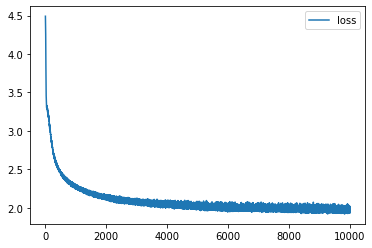

Шаблон функции `generate_sample` также доступен ниже. Вы можете как дозаполнить его, так и написать свою собственную функцию с нуля. Не забывайте, что все примеры в обучающей выборке начинались с токена `<sos>`.

In [48]:
'''
def generate_sample(char_rnn, seed_phrase=None, max_length=200, temperature=1.0, device=device):

    #The function generates text given a phrase of length at least SEQ_LENGTH.
    #:param seed_phrase: prefix characters. The RNN is asked to continue the phrase
    #:param max_length: maximum output length, including seed_phrase
    #:param temperature: coefficient for sampling.  higher temperature produces more chaotic outputs,
    #                    smaller temperature converges to the single most likely output


    if seed_phrase is not None:
        x_sequence = [token_to_idx['<sos>']] + [token_to_idx[token] for token in seed_phrase]
    else:
        x_sequence = [token_to_idx['<sos>']]

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64).to(device)

    #feed the seed phrase, if any

    # your code here

    return ''.join([tokens[ix] for ix in x_sequence.cpu().data.numpy()[0]])
'''

def generate_sample(prime_str='A', predict_len=100, temperature=0.8):
    hidden = decoder.init_hidden()
    prime_input = char_tensor(prime_str)
    predicted = prime_str

    # Use priming string to "build up" hidden state
    for p in range(len(prime_str) - 1):
        _, hidden = decoder(prime_input[p], hidden)
    inp = prime_input[-1]

    for p in range(predict_len):
        output, hidden = decoder(inp, hidden)

        # Sample from the network as a multinomial distribution
        output_dist = output.data.view(-1).div(temperature).exp()
        top_i = torch.multinomial(output_dist, 1)[0]

        # Add predicted character to string and use as next input
        predicted_char = all_characters[top_i]
        predicted += predicted_char
        inp = char_tensor(predicted_char)

    return predicted
print(generate_sample(prime_str=' мой дядя самых честных правил', predict_len=500, temperature=0.8))

 мой дядя самых честных правил#M1YXUTXS70000EEq00#YXUXLWX!",1PO1XWR1YZON70000EEECq00"X1YXUOZOV1WO1"ZXK51TJT1VXPRW,O0R1UOW!TLJWR1UOWR51UOVOWWXS0YOUR"O51NR"W+S1#P1!X.0R1RV1R1!OUR1XNWOS0YZONWXS1VXU'WJ1VXPO"1WO1!UOQJZOWWXS0YXNR"J",.1"ZONJ1L1UOVW+S1!UONJZ/50U.KRZ+N,1OS1VXMU#1XNJW,O0WO1L!TJZOWWX1V#QJVONOW50!1OMX1!JVXUOWRS0#YXVWXV1WO1YXUOW,/50!JNJ."1X'OW,OV1WO1YXNZ#MR50000EEqE00YXLOZWX1NJLOWW+S1$UJNRW+S1!UJL+50VXS1L!OV1WOV1ZXMNJ",1QJNR'R1"R%XNR"70000EsC00"JT51PO1XWR1!XNOZLOW,O50R1!XLXRW+51LX"1!OZN&O1!X!ON70000EEC00R1"X1PJZ1WJ!WJ.1W


Пример текста сгенерированного обученной моделью доступен ниже. Не страшно, что в тексте много несуществующих слов. Используемая модель очень проста: это простая классическая RNN.

TypeError: generate_sample() got multiple values for argument 'predict_len'

### Сдача задания
Сгенерируйте десять последовательностей длиной 500, используя строку ' мой дядя самых честных правил'. Температуру для генерации выберите самостоятельно на основании визуального качества генериуремого текста. Не забудьте удалить все технические токены в случае их наличия.

Сгенерированную последовательность сохрание в переменную `generated_phrase` и сдайте сгенерированный ниже файл в контест.

In [ ]:
seed_phrase = ' мой дядя самых честных правил'

In [ ]:
generated_phrases = # your code here

# For example:

# generated_phrases = [
#     generate_sample(
#         model,
#         ' мой дядя самых честных правил',
#         max_length=500,
#         temperature=1.
#     ).replace('<sos>', '')
#     for _ in range(10)
# ]

In [ ]:
# do not change the code in the block below
# __________start of block__________

import json
if 'generated_phrases' not in locals():
    raise ValueError("Please, save generated phrases to `generated_phrases` variable")

for phrase in generated_phrases:

    if not isinstance(phrase, str):
        raise ValueError("The generated phrase should be a string")

    if len(phrase) != 500:
        raise ValueError("The `generated_phrase` length should be equal to 500")

    assert all([x in set(tokens) for x in set(list(phrase))]), 'Unknown tokens detected, check your submission!'


submission_dict = {
    'token_to_idx': token_to_idx,
    'generated_phrases': generated_phrases
}

with open('submission_dict.json', 'w') as iofile:
    json.dump(submission_dict, iofile)
print('File saved to `submission_dict.json`')
# __________end of block__________

На этом задание завершено. Поздравляем!